In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('../data/creditcard.csv')

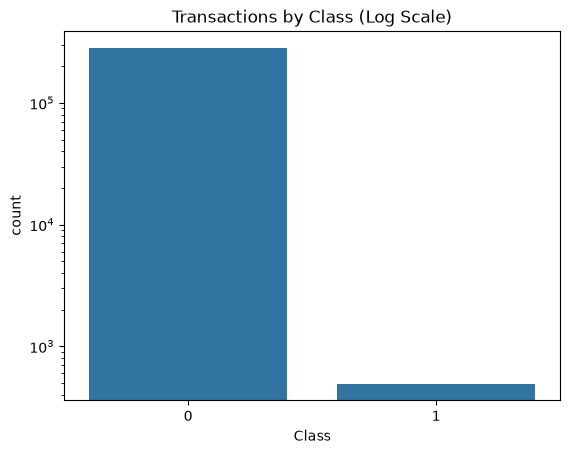

In [2]:
sns.countplot(x="Class", data=df)
plt.yscale('log')
plt.title("Transactions by Class (Log Scale)")
plt.savefig("../figures/Class_Balance.png",dpi=150,bbox_inches='tight')
plt.show()

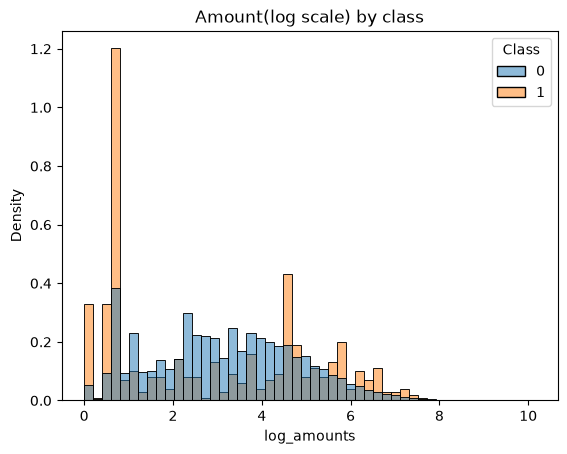

In [3]:
df["log_amounts"]=np.log1p(df["Amount"])
sns.histplot(x="log_amounts",data=df,hue="Class",stat="density",common_norm=False,bins=50)
plt.title("Amount(log scale) by class")
plt.savefig("../figures/Amount_by_class.png",dpi=150,bbox_inches='tight')
plt.show()

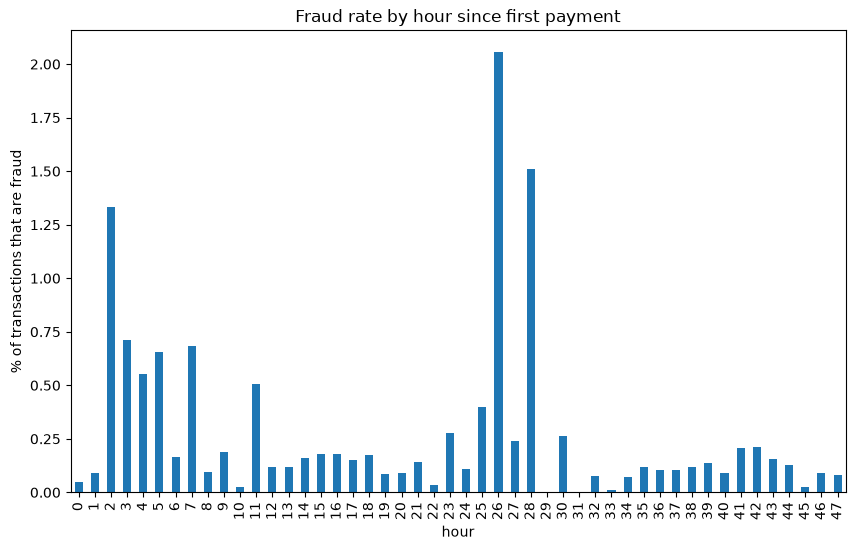

In [4]:
df["hour"]=(df["Time"]//3600).astype(int)
by_hour=df.groupby("hour")["Class"].agg(fraud="sum",total="count")
by_hour["fraud_rate_%"]=100*by_hour["fraud"]/by_hour["total"]
by_hour["fraud_rate_%"].plot(kind="bar",figsize=(10,6))
plt.title("Fraud rate by hour since first payment")
plt.ylabel("% of transactions that are fraud")
plt.savefig("../figures/fraud_by_hour.png",dpi=150,bbox_inches="tight")
plt.show()

In [ ]:
v_cols=[f"V{i}"for  i in range(1,29)]
fraud_mean=df[df["Class"]==1][v_cols].mean()
normal_mean=df[df["Class"]==0][v_cols].mean()
separation=((fraud_mean-normal_mean)/df[v_cols].std()).abs().sort_values(ascending=False)
separation.head(10)

V17    7.861863
V14    7.285436
V12    6.275236
V10    5.222673
V16    4.732777
V3     4.646614
V7     4.509253
V11    3.729500
V4     3.213497
V18    2.684633
dtype: float64